# ENSO PCA on ERA5 sea surface temperature

Monthly ERA5 SST (Copernicus CDS, `reanalysis-era5-single-levels-monthly-means`), 1980–2023.
Steps: load the CDS download, crop to the tropical Pacific, coarsen to 2°, remove the seasonal cycle,
compute EOFs/PCs with area weighting, and compare PC1 with the Niño3.4 index.

**Data:** put the zip (or the .nc inside it) from the CDS *Your requests* page in `data/` next to this
notebook, or leave it in your Downloads folder. The next cell finds it.

In [1]:
# ---- settings ----
LAT_MIN, LAT_MAX = -20, 20      # tropical band
LON_MIN, LON_MAX = 120, 280     # 120E to 80W, in 0-360 degrees east
GRID_DEG = 2.0                  # coarsen to this resolution (ERA5 native is 0.25)
CLIM_YEARS = ("1991", "2020")   # base period for the seasonal climatology
DETREND = True                  # remove the linear warming trend at each grid point
N_MODES = 10

In [2]:
from pathlib import Path
import glob, zipfile
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

here = Path.cwd()
data_dir = here / "data"
data_dir.mkdir(exist_ok=True)

def find_input():
    # CDS names the monthly-means file data_stream-moda*.nc; it may sit in a subfolder or still be zipped
    for folder in [data_dir, Path.home() / "Downloads"]:
        hits = sorted(glob.glob(str(folder / "**" / "data_stream-moda*.nc"), recursive=True))
        if hits:
            return Path(hits[0])
        for h in sorted(glob.glob(str(folder / "*.zip")), key=lambda p: Path(p).stat().st_mtime, reverse=True):
            with zipfile.ZipFile(h) as z:
                ncs = [n for n in z.namelist() if n.startswith("data_stream-moda") and n.endswith(".nc")]
                if ncs:
                    z.extract(ncs[0], data_dir)
                    return data_dir / ncs[0]
    raise FileNotFoundError("No ERA5 data_stream-moda*.nc (or zip containing it) in data/ or Downloads")

nc_path = find_input()
print("Reading", nc_path)
ds = xr.open_dataset(nc_path)
ds

Reading C:\Users\parha\Python\enso_autoencoder\data\CDS Data\data_stream-moda_stepType-avgua.nc


<xarray.Dataset>
Dimensions:     (valid_time: 528, latitude: 161, longitude: 1440)
Coordinates:
    number      int64 ...
  * valid_time  (valid_time) datetime64[ns] 1980-01-01 1980-02-01 ... 2023-12-01
  * latitude    (latitude) float64 20.0 19.75 19.5 19.25 ... -19.5 -19.75 -20.0
  * longitude   (longitude) float64 -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
    expver      (valid_time) object ...
Data variables:
    sst         (valid_time, latitude, longitude) float32 ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-19T12:36 GRIB to CDM+CF via cfgrib-0.9.1...

In [3]:
# Normalise names: new CDS files use valid_time/latitude/longitude, variable 'sst' in kelvin
ren = {k: v for k, v in {"valid_time": "time", "latitude": "lat", "longitude": "lon"}.items() if k in ds.dims or k in ds.coords}
ds = ds.rename(ren)
sst = ds["sst"] - 273.15
sst = sst.drop_vars([c for c in sst.coords if c not in ("time", "lat", "lon")])

# longitudes -180..180 -> 0..360 so the Pacific is contiguous across the date line
sst = sst.assign_coords(lon=sst.lon % 360).sortby("lon").sortby("lat")
sst = sst.sel(lat=slice(LAT_MIN, LAT_MAX), lon=slice(LON_MIN, LON_MAX))

# coarsen to GRID_DEG by block averaging (ignores land NaNs within a block)
step = int(round(GRID_DEG / float(abs(sst.lon[1] - sst.lon[0]))))
if step > 1:
    sst = sst.coarsen(lat=step, lon=step, boundary="trim").mean()
sst = sst.sel(time=slice("1980", "2023"))
print(dict(sst.sizes), "|", str(sst.time.values[0])[:7], "to", str(sst.time.values[-1])[:7])

{'time': 528, 'lat': 20, 'lon': 80} | 1980-01 to 2023-12


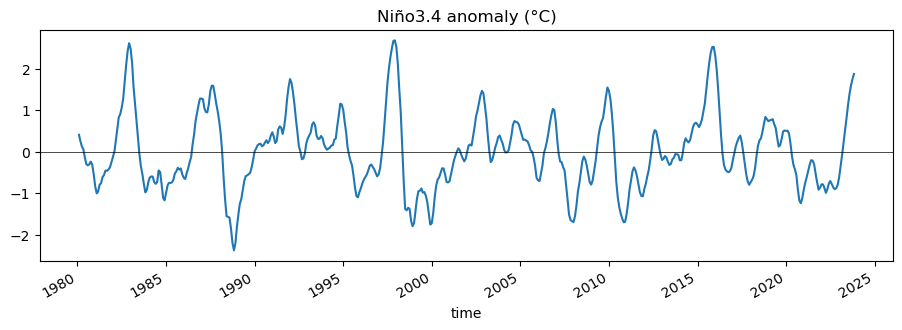

In [4]:
# Anomalies: subtract monthly climatology, optionally remove linear trend
clim = sst.sel(time=slice(*CLIM_YEARS)).groupby("time.month").mean("time")
anom = sst.groupby("time.month") - clim
anom = anom.drop_vars("month")
if DETREND:
    fit = anom.polyfit("time", 1, skipna=True)
    anom = anom - xr.polyval(anom.time, fit.polyfit_coefficients)

# Niño3.4 index (5S-5N, 170W-120W), 3-month running mean
nino34 = anom.sel(lat=slice(-5, 5), lon=slice(190, 240))
w34 = np.cos(np.deg2rad(nino34.lat))
nino34 = nino34.weighted(w34).mean(("lat", "lon")).rolling(time=3, center=True).mean()
nino34.plot(figsize=(11, 3)); plt.axhline(0, c="k", lw=.5); plt.title("Niño3.4 anomaly (°C)"); plt.show()

In [5]:
# EOFs: weight by sqrt(cos lat) so each grid cell counts by its area
weights = np.sqrt(np.cos(np.deg2rad(anom.lat)))
stacked = (anom * weights).stack(space=("lat", "lon"))
ocean = stacked.notnull().all("time")
X = stacked.sel(space=ocean).values          # (time, ocean points)
print("matrix:", X.shape)

pca = PCA(n_components=N_MODES).fit(X)
pcs = pca.transform(X)
pcs_std = pcs / pcs.std(0)                   # PCs in standard deviations
evr = pca.explained_variance_ratio_
print("explained variance:", np.round(evr, 3))

# EOF maps as regression of the (unweighted) SST anomaly in °C on each standardised PC
raw = anom.stack(space=("lat", "lon")).sel(space=ocean).values
reg = np.full((N_MODES, stacked.sizes["space"]), np.nan)
reg[:, ocean.values] = pcs_std.T @ (raw - raw.mean(0)) / len(raw)
eofs = xr.DataArray(reg, coords={"mode": range(1, N_MODES + 1), "space": stacked.space}, dims=("mode", "space")).unstack("space")

matrix: (528, 1572)
explained variance: [0.525 0.114 0.049 0.036 0.029 0.02  0.02  0.015 0.013 0.012]


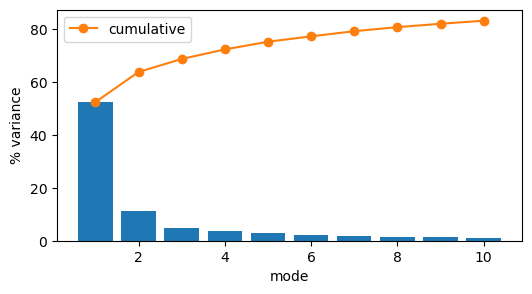

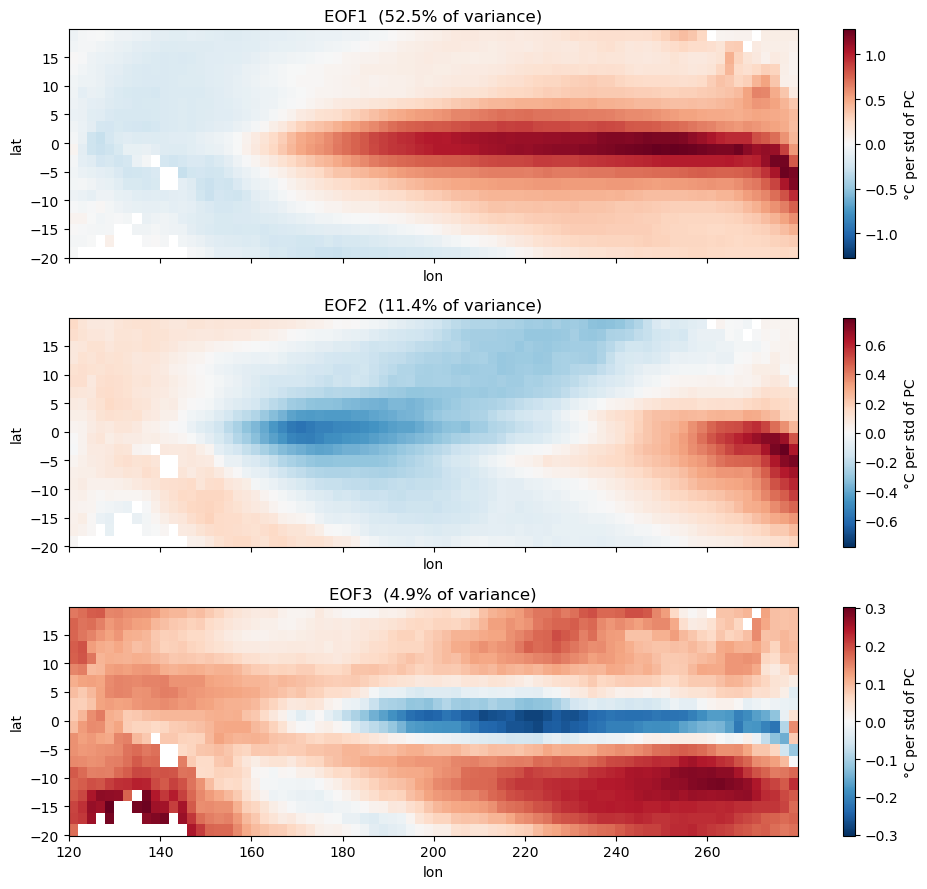

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(range(1, N_MODES + 1), evr * 100)
ax.plot(range(1, N_MODES + 1), np.cumsum(evr) * 100, "o-", c="C1", label="cumulative")
ax.set_xlabel("mode"); ax.set_ylabel("% variance"); ax.legend(); plt.show()

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for k, ax in enumerate(axes):
    eofs.sel(mode=k + 1).plot(ax=ax, cmap="RdBu_r", center=0, cbar_kwargs={"label": "°C per std of PC"})
    ax.set_title(f"EOF{k+1}  ({evr[k]*100:.1f}% of variance)")
plt.tight_layout(); plt.show()

corr(PC1, Niño3.4) = +0.96
corr(PC2, Niño3.4) = -0.19
corr(PC3, Niño3.4) = -0.13


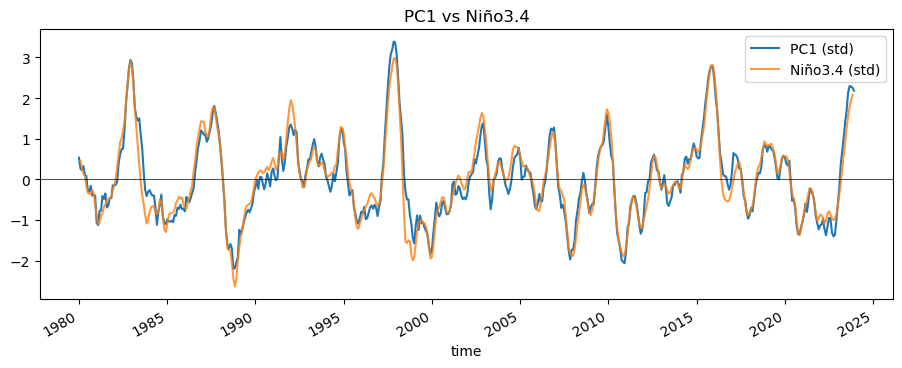

In [7]:
pc = xr.DataArray(pcs_std, coords={"time": anom.time, "mode": range(1, N_MODES + 1)}, dims=("time", "mode"))
# sign convention: PC1 positive during El Niño
valid = nino34.notnull()
if np.corrcoef(pc.sel(mode=1)[valid], nino34[valid])[0, 1] < 0:
    pc.loc[dict(mode=1)] *= -1; eofs.loc[dict(mode=1)] *= -1

for k in (1, 2, 3):
    r = np.corrcoef(pc.sel(mode=k)[valid], nino34[valid])[0, 1]
    print(f"corr(PC{k}, Niño3.4) = {r:+.2f}")

fig, ax = plt.subplots(figsize=(11, 3.5))
(pc.sel(mode=1)).plot(ax=ax, label="PC1 (std)")
(nino34 / nino34.std()).plot(ax=ax, label="Niño3.4 (std)", alpha=.8)
ax.axhline(0, c="k", lw=.5); ax.legend(); ax.set_title("PC1 vs Niño3.4"); plt.show()

In [8]:
# Save results for later use
xr.Dataset({"eof": eofs, "pc": pc, "nino34": nino34, "explained_variance": ("mode", evr)}).to_netcdf(data_dir / "era5_sst_pca.nc")
print("saved", data_dir / "era5_sst_pca.nc")

saved C:\Users\parha\Python\enso_autoencoder\data\era5_sst_pca.nc
